# **Задание 1.**

## **1. Постановка задачи**

### **1.1. Бизнес-постановка**

Сетевые атаки наносят бизнесу прямой ущерб (простои, утечки, потери), а аналитики SOC не успевают вручную просматривать весь трафик. Нужна система обнаружения вторжений, которая автоматически по параметрам сетевого потока определяет, атака это или норма, и передаёт аналитику только подозрительные события.

**Бизнес-метрика:** доля обнаруженных атак при приемлемом уровне ложных срабатываний – система не должна «пропускать» атаки и при этом не должна «заваливать» аналитика ложными тревогами.

### **1.2. Постановка ML-задачи**

**Тип задачи:** бинарная классификация.

**Целевая переменная:** `label`
- `0` – Normal (легитимный трафик),
- `1` – Attack (вредоносный трафик).

### **1.3. Набор данных**

Для решения задачи используется датасет **UNSW-NB15** (Moustafa & Slay, 2015), созданный в киберполигоне Австралийского центра кибербезопасности. Данные представляют собой гибрид реального нормального трафика и 9 видов синтетических атак (Fuzzers, Analysis, Backdoors, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms).

- **train:** 175 341 запись, **test:** 82 332 записи, 45 колонок;
- есть `label` (бинарная) и `attack_cat` (тип атаки).


## **2. Выбор метрики**

В качестве основной метрики выбирается **F1-score** (для оценки качества при стандартном пороге), а в качестве дополнительных – F-beta score (смещенная в сторону полноты/Recall) и ROC-AUC (для оценки общей способности модели разделять классы).

**Обоснование:**

В задачах кибербезопасности, классы несбалансированы, поэтому метрика Accuracy недопустима – модель может просто предсказывать «всегда атака» с точностью 68%.

Если оптимизировать только Precision, модель будет ловить только очевидные атаки, пропуская сложные. Если оптимизировать только Recall, мы получим огромное количество ложных срабатываний и «усталость от алертов».

F1-score идеально балансирует эти крайности. Однако, поскольку пропуск атаки (False Negative) наносит бизнесу больший ущерб, чем ложная тревога (False Positive), мы также будем использовать F-beta score с β=2 и Recall имеет больший вес, чем Precision.

При сильном дисбалансе ROC-AUC может быть обманчиво высоким, так как FPR остается низким за счет огромного количества True Negative, поэтому мы будем смотреть на кривую Precision-Recall как на дополнительный инструмент контроля ложных тревог при разных порогах.

## **3. EDA**

### **3.1. Знакомство с данными**


Импортируем необходимые библиотеки и выгружаем обучающую выборку (train-set) как df для первоначального анализа данных.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import kagglehub
path = kagglehub.dataset_download("mrwellsdavid/unsw-nb15")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'unsw-nb15' dataset.
Path to dataset files: /kaggle/input/unsw-nb15


In [ ]:
!ls -R /kaggle/input/unsw-nb15

/kaggle/input/unsw-nb15:
NUSW-NB15_features.csv	UNSW-NB15_3.csv		   UNSW_NB15_testing-set.csv
UNSW-NB15_1.csv		UNSW-NB15_4.csv		   UNSW_NB15_training-set.csv
UNSW-NB15_2.csv		UNSW-NB15_LIST_EVENTS.csv


In [ ]:
# При загрузке CSV файлов, выяснилось, что у тестовой и обучающей выборки перепутаны названия на kaggle.
# Проводить EDA будем на обучающей выборке, поэтому загружаем UNSW_NB15_testing-set.csv
df = pd.read_csv("/kaggle/input/unsw-nb15/UNSW_NB15_testing-set.csv", low_memory=False)

In [ ]:
df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [ ]:
df.columns

Index(['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='object')

In [ ]:
df.shape

(175341, 45)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  si

In [ ]:
df.dtypes

,0
id,int64
dur,float64
proto,object
service,object
state,object
spkts,int64
dpkts,int64
sbytes,int64
dbytes,int64
rate,float64


In [ ]:
df.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,...,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,87671.000000,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,...,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,50616.731112,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,...,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,1.000000,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,43836.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,87671.000000,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,131506.000000,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,...,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,175341.000000,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


In [ ]:
df.isna().sum()

,0
id,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.select_dtypes(include='object').nunique()

,0
proto,133
service,13
state,9
attack_cat,10


###Выводы по знакомству с данными:

1. Набор данных содержит 175 341 запись и 45 признаков.

2. В датасете отсутствуют пропущенные значения и полные дубликаты строк.

3. В данных 30 целочисленных (int64) и 11 вещественных (float64) признаков, а также 4 категориальных (object).

4. Признак proto имеет много уникальных значений (133), что может потребовать объединения редких протоколов в группу "other" при кодировании. Признаки service (13) и state (9) имеют мало уникальных значений и легко закодируются через One-Hot Encoding.

### **3.2. Справочник признаков (features)**

Для корректной интерпретации данных загружаем справочник features_df, который содержит физическое описание всех исходных признаков датасета. Это необходимо для понимания того, какие именно характеристики сетевого трафика мы анализируем.

In [ ]:
features_df = pd.read_csv("/kaggle/input/unsw-nb15/NUSW-NB15_features.csv", encoding='latin-1')
features_df.shape

(49, 4)

In [ ]:
features_df

,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol
5,6,state,nominal,Indicates to the state and its dependent proto...
6,7,dur,Float,Record total duration
7,8,sbytes,Integer,Source to destination transaction bytes
8,9,dbytes,Integer,Destination to source transaction bytes
9,10,sttl,Integer,Source to destination time to live value


### Вывод по справочнику признаков:

**Типы признаков:** Большинство признаков являются числовыми (Integer, Float), описывающими параметры сетевого потока. 4 признака – категориальные (nominal), 3 – бинарные (binary).

**Исключенные признаки:** В готовом train/test наборе отсутствуют признаки с исходными IP-адресами (srcip, dstip), портами (sport, dsport) и временными метками (Stime, Ltime). Это было сделано авторами для предотвращения переобучения (data leakage), чтобы модель училась на паттернах поведения, а не на конкретных адресах.

**Целевые переменные: attack_cat (мультикласс) и label (бинарный) – это наши таргеты.
Поскольку в рамках данной работы решается задача бинарной классификации, основной целевой переменной будет label.

### **3.3 Визуализация данных**

**Дисбаланс классов**

Построим график Countplot, чтобы оценить дисбаланс целевых переменных (label и attack_cat), так как от этого зависит выбор метрики и стратегии обучения.

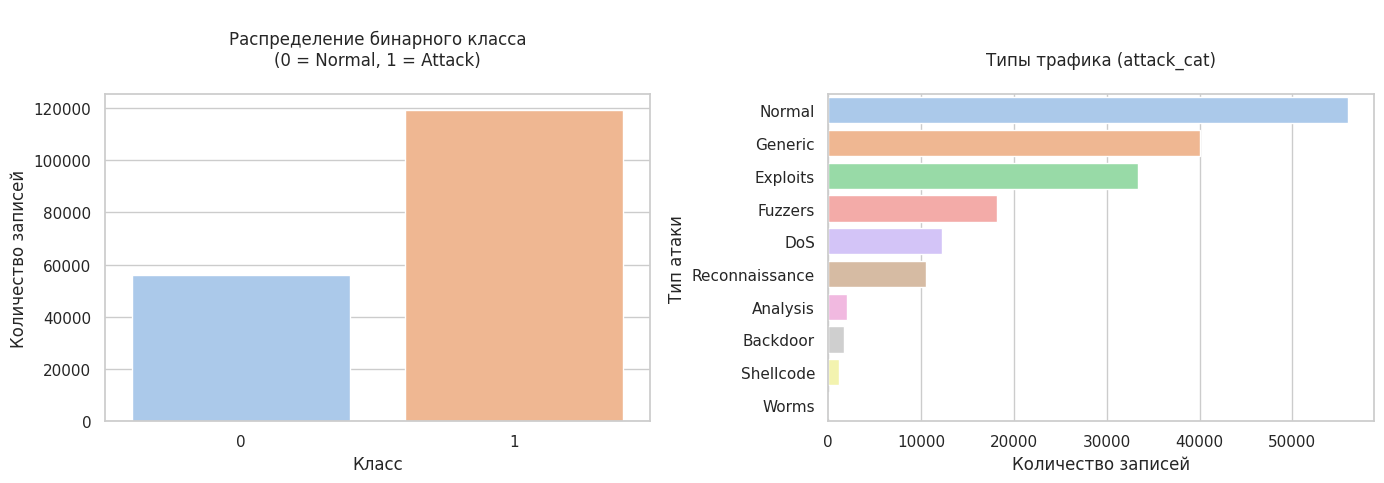

In [52]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# 1. Бинарный таргет (label)
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='label', palette='pastel')
plt.title('\nРаспределение бинарного класса\n(0 = Normal, 1 = Attack)\n')
plt.xlabel('Класс')
plt.ylabel('Количество записей')

# 2. Мультиклассовый таргет (attack_cat)
plt.subplot(1, 2, 2)
sns.countplot(data=df, y='attack_cat',
              order=df['attack_cat'].value_counts().index,
              palette='pastel')
plt.title('\nТипы трафика (attack_cat)\n')
plt.xlabel('Количество записей')
plt.ylabel('Тип атаки')

plt.tight_layout()
plt.show()

**Вывод по результатам визуализации целевых переменных:**

На графиках представлено распределение записей по классам:

Бинарный таргет (label): Наблюдается умеренный дисбаланс классов. В тренировочной выборке вредоносный трафик преобладает над нормальным  и составляет примерно 68% от всех данных (около 119 тыс. записей против 56 тыс.). Это важно учесть, при построении модель не должна быть смещена в сторону предсказания одного класса.

Мультиклассовый таргет (attack_cat): Внутри класса атак наблюдается сильная неоднородность. Явными лидерами являются атаки типа Generic и Exploits. В то же время такие атаки, как Worms, Shellcode, Backdoor и Analysis, представлены единичными записями.

*Такой сильный дисбаланс внутри attack_cat подтверждает правильность выбора бинарной постановки задачи (атака/норма). Если бы мы решали задачу мультиклассовой классификации, модели было бы крайне сложно выучить редкие классы. В рамках же бинарной задачи все редкие атаки объединяются в один класс, что делает выборку более сбалансированной и упрощает обучение.*

**Числовые признаки vs Таргет**

Построим графики Boxplot для визуализации числовых признаков sbytes, dbytes, sttl. Нам важно понять, насколько сильно различаются эти показатели у нормального трафика (label=0) и у атак (label=1), чтобы оценить предсказательную силу признаков.

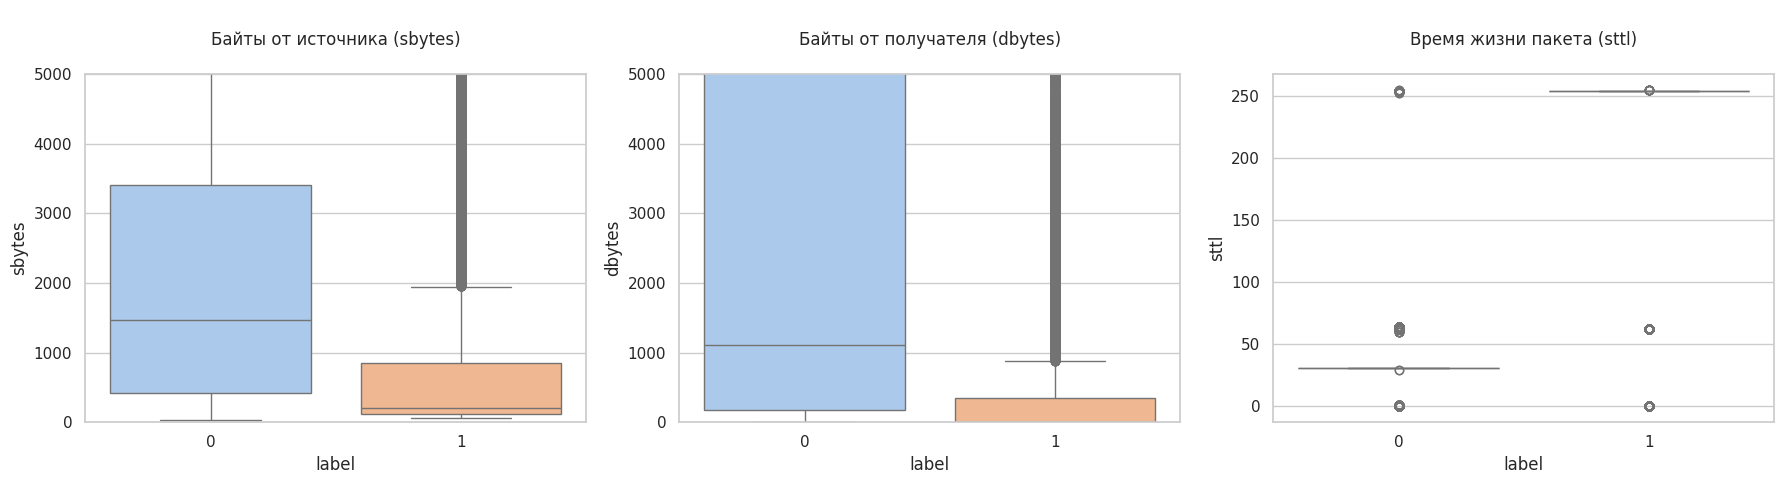

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Байты от источника (sbytes)
sns.boxplot(data=df, x='label', y='sbytes', hue='label', palette='pastel', legend=False, ax=axes[0])
axes[0].set_title('\nБайты от источника (sbytes)\n')
axes[0].set_ylim(0, 5000) # Ограничиваем Y, чтобы выбросы не ломали график

# Байты от получателя (dbytes)
sns.boxplot(data=df, x='label', y='dbytes', hue='label', palette='pastel', legend=False, ax=axes[1])
axes[1].set_title('\nБайты от получателя (dbytes)\n')
axes[1].set_ylim(0, 5000)

# Время жизни пакета (sttl)
sns.boxplot(data=df, x='label', y='sttl', hue='label', palette='pastel', legend=False, ax=axes[2])
axes[2].set_title('\nВремя жизни пакета (sttl)\n')

plt.tight_layout()
plt.show()

**Вывод по результатам визуализации числовых признаков:**

Байты от источника (sbytes):

Наблюдается ярко выраженная разница в медианах. У нормального трафика медианный объем данных (1400 байт), чем у атак (менее 200 байт). Это указывает на то, что типичные легитимные сессии передают больший объем данных. Однако у класса атак присутствует огромное количество экстремальных выбросов. Это свидетельствует о том, что некоторые типы атак (например, отправка больших полезных нагрузок или DDoS) генерируют аномально высокий исходящий трафик.

Байты от получателя (dbytes):

Наблюдается еще более сильный контраст. У нормального трафика «ящик» огромный, медиана примерно равна 1000. У атак же подавляющее большинство значений прижато к нулю. Это логично: многие атаки (например, SYN-флуд, сканирование портов) представляют собой короткие запросы, на которые сервер не отвечает большими объемами данных (или отвечает ошибками). Также у класса атак на графике видно огромное количество выбросов. Это означает, что существуют специфические типы атак, при которых сервер вынужден отправлять аномально большие объемы данных. Признак dbytes обладает высокой разделяющей способностью.

Время жизни пакета (sttl):

Значения этого признака не разбросаны по всей шкале, а сгруппированы в нескольких конкретных точках. У класса атак медиана находится около 254, в то время как у нормального трафика основная масса значений сконцентрирована в нижнем диапазоне (около 30).

**Категориальные признаки vs Таргет**

Для анализа категориальных признаков построим countplot с разбивкой на нормальный трафик и атаки, для того чтобы визуально оценить, в каких именно протоколах и состояниях соединения концентрируются вредоносные события.

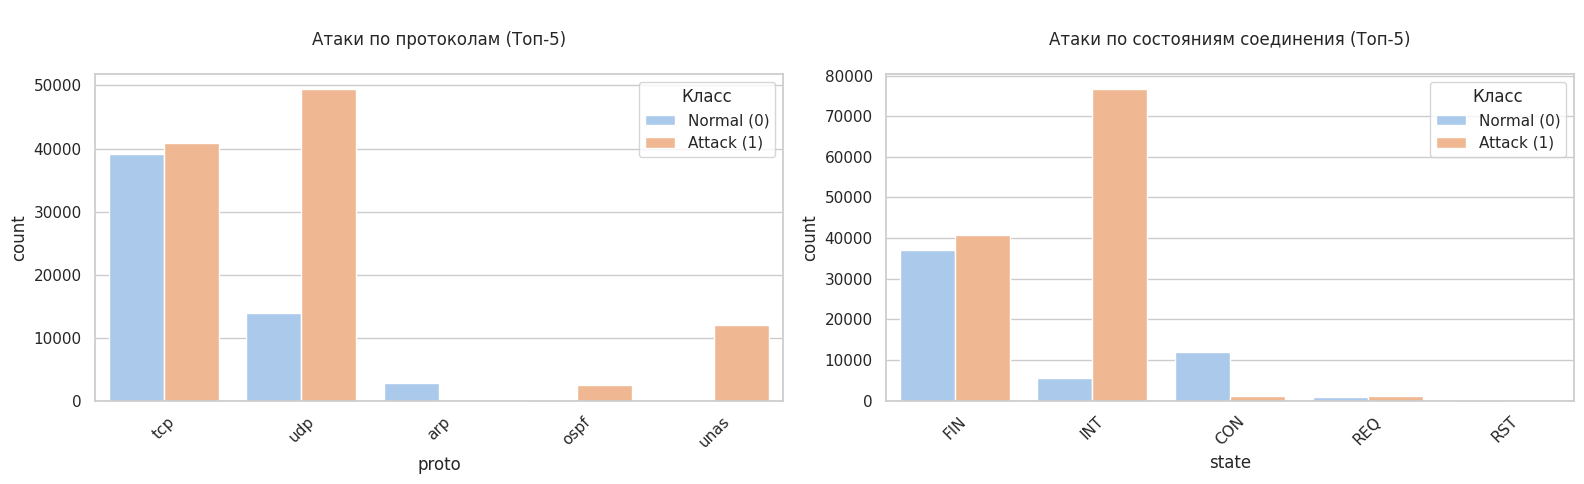

In [66]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Протоколы (топ-5)
top_proto = df['proto'].value_counts().head(5).index
sns.countplot(data=df[df['proto'].isin(top_proto)], x='proto', hue='label',
              palette='pastel', ax=axes[0])
axes[0].set_title('\nАтаки по протоколам (Топ-5)\n')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Класс', labels=['Normal (0)', 'Attack (1)'])

# Состояния соединения (топ-5)
top_state = df['state'].value_counts().head(5).index
sns.countplot(data=df[df['state'].isin(top_state)], x='state', hue='label',
              palette='pastel', ax=axes[1])
axes[1].set_title('\nАтаки по состояниям соединения (Топ-5)\n')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Класс', labels=['Normal (0)', 'Attack (1)'])

plt.tight_layout()
plt.show()

**Вывод по результатам визуализации категориальных признаков:**

Протокол (proto):

Трафик смещен в сторону **tcp**, однако в протоколе **udp** наблюдается явный перевес в сторону атак (около 50 тыс. против 14 тыс. у нормы). Это можно объяснить тем, что udp часто используется для DDoS-атак. Также присутствует протокол unas, который используется исключительно для атак.

Состояние соединения (state):

В состоянии **FIN** (корректное завершение) наблюдается примерно равное количество обоих классов с небольшим перевесом в сторону атак.
Состояние **INT** (прерванное соединение) встречается почти исключительно в атаках (76 тыс. атак против 5 тыс. нормы) – это классический признак SYN-флуда и других атак, когда соединение не завершается корректно. В состоянии **CON** (установленное соединение) преобладает нормальный трафик.

**Корреляционная матрица**

Построим тепловую карту (heatmap) для выявления мультиколлинеарности и оценки того, как признаки взаимодействуют друг с другом.

Поскольку в обучающей выборке содержится 45 колонок, полная матрица корреляций получается слишком большой и нечитаемой. Чтобы этого избежать, для визуализации отберем только числовые признаки и Топ-15 признаков, имеющих наибольшую корреляцию с бинарным таргетом label.

Также построим барчарт связи с таргетом, чтобы оценить насколько признаки важны для для предсказания атаки.

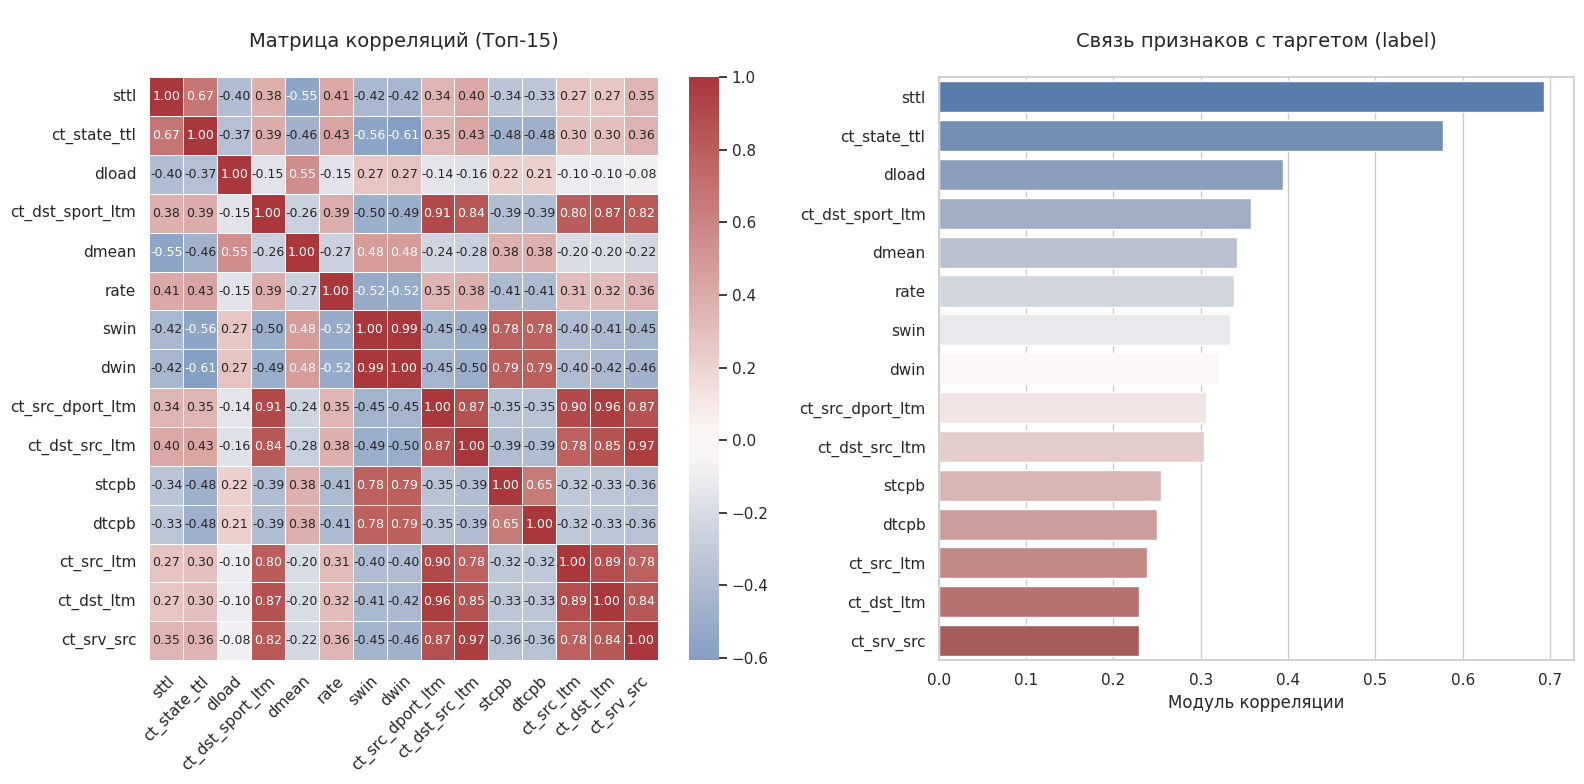

In [72]:
num_cols = df.select_dtypes(include=['int64', 'float64']).drop(columns=['id'])
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Находим Топ-15 признаков по модулю корреляции с таргетом
corr_matrix = num_cols.corr()
top_15 = corr_matrix['label'].drop('label').abs().sort_values(ascending=False).head(15)
top_features = top_15.index

# Строим матрицу только для отобранных признаков
sns.heatmap(num_cols[top_features].corr(),
            cmap='vlag', center=0,
            annot=True, fmt=".2f",
            linewidths=.5, annot_kws={"size": 9},
            ax=axes[0])
axes[0].set_title('\nМатрица корреляций (Топ-15)\n', fontsize=14)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)

# Строим связь признаков с таргетом
sns.barplot(x=top_15.values, y=top_15.index, palette='vlag', ax=axes[1])
axes[1].set_title('\nСвязь признаков с таргетом (label)\n', fontsize=14)
axes[1].set_xlabel('Модуль корреляции')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

**Вывод по результатам визуализации корреляционной матрицы:**

1. **Связь с целевой переменной**

    Наибольшую связь с атакой показывают три признака:

    sttl (0.68) – время жизни пакета. Как мы выяснили ранее, злоумышленники часто используют  максимальные значения TTL (254) при генерации атак из локальной сети, в то время как нормальный трафик проходит через множество маршрутизаторов и его TTL снижается.

    ct_state_ttl (0.58) – счетчик соединений с одинаковым TTL. Этот признак напрямую связан с предыдущим и помогает модели отслеживать подозрительную активность по повторяющимся параметрам.

    dload (0.39) показывает скорость загрузки данных от получателя. У атак этот показатель часто либо аномально высок (при DDoS), либо близок к нулю (при сканировании портов).

*Эти три характеристики несут в себе больше всего информации для модели, так как напрямую отражают поведенческие паттерны вредоносного трафика. Их стоит использовать в первую очередь при обучении.*

2. **Мультиколлинеарность**

    На матрице видно, что некоторые признаки дублируют друг друга:

    Группа счетчиков соединений (ct_dst_sport_ltm, ct_src_dport_ltm, ct_dst_src_ltm, ct_src_ltm, ct_dst_ltm) имеет очень высокую корреляцию друг с другом (от 0.80 до 0.97).

    Размеры окон swin и dwin практически идентичны (0.99).

*Если подать в модель все дублирующие друг друга признаки одновременно, это может ухудшить ее работу. Поэтому на этапе предобработки для линейных моделей мы оставим только один признак из каждой группы дубликатов.*

## **Вывод:**

В ходе разведочного анализа данных (EDA) были выявлены ключевые характеристики датасета, которые определят наш дальнейший подход к предобработке и моделированию.

**Чистота данных:** В тренировочной выборке отсутствуют пропуски и полные дубликаты строк. Данные готовы к анализу.

**Дисбаланс классов:** Наблюдается умеренный перевес атак (68%) над нормальным трафиком (32%). Внутри типа атак (Generic, Exploits) наблюдается сильный дисбаланс, что подтверждает правильность выбора бинарной постановки задачи.

**Категориальные признаки:** Признаки proto, service и state обладают высокой предсказательной силой (особенно state = INT для атак). Перед подачей в модель их необходимо закодировать (One-Hot или Label Encoding). Признак proto требует объединения редких значений в группу "other".

**Числовые признаки и выбросы:** Распределения числовых признаков (например, sbytes, dload) сильно скошены, присутствует множество выбросов. В задачах NIDS выбросы являются индикаторами атак (DDoS, брутфорс), поэтому удалять их нельзя. Для линейных моделей потребуется масштабирование (например, RobustScaler).

**Мультиколлинеарность:** Выявлены группы сильно коррелирующих признаков (счетчики соединений ct_..., размеры окон swin/dwin).